In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor, OLSInfluence
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [2]:
df = pd.read_csv("Housing.csv")
print("Dataset shape:", df.shape)

Dataset shape: (545, 13)


Regression dataset: 545 rows
           count          mean           std        min        25%        50%  \
price      545.0  4.766729e+06  1.870440e+06  1750000.0  3430000.0  4340000.0   
area       545.0  5.150541e+03  2.170141e+03     1650.0     3600.0     4600.0   
bedrooms   545.0  2.965138e+00  7.380639e-01        1.0        2.0        3.0   
bathrooms  545.0  1.286239e+00  5.024696e-01        1.0        1.0        1.0   
stories    545.0  1.805505e+00  8.674925e-01        1.0        1.0        2.0   
parking    545.0  6.935780e-01  8.615858e-01        0.0        0.0        0.0   

                 75%         max  
price      5740000.0  13300000.0  
area          6360.0     16200.0  
bedrooms         3.0         6.0  
bathrooms        2.0         4.0  
stories          2.0         4.0  
parking          1.0         3.0  


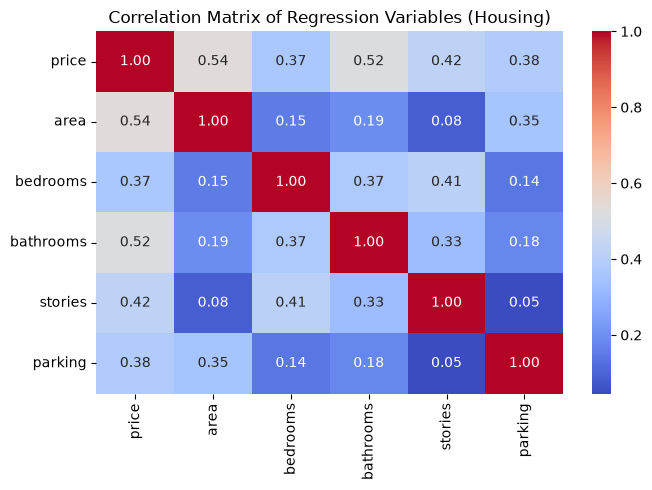

In [3]:
target = "price"
predictors = ["area", "bedrooms", "bathrooms", "stories", "parking"]
reg_df = df[[target] + predictors].dropna().copy()
print(f"Regression dataset: {len(reg_df)} rows")
print(reg_df.describe().T)

plt.figure(figsize=(7, 5))
sns.heatmap(reg_df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Matrix of Regression Variables (Housing)")
plt.tight_layout()
plt.show()

In [4]:
X, y = reg_df[predictors], reg_df[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print("Train set:", len(X_train), "Test set:", len(X_test))

model = sm.OLS(y_train, sm.add_constant(X_train)).fit()
print(model.summary())

coefficients = pd.DataFrame({
    "Coefficient": model.params,
    "Std Error": model.bse,
    "t-statistic": model.tvalues,
    "p-value": model.pvalues
})
print(coefficients.round(4))

Train set: 436 Test set: 109
                            OLS Regression Results                            
Dep. Variable:                  price   R-squared:                       0.562
Model:                            OLS   Adj. R-squared:                  0.557
Method:                 Least Squares   F-statistic:                     110.4
Date:                Thu, 29 Oct 2026   Prob (F-statistic):           7.71e-75
Time:                        04:05:43   Log-Likelihood:                -6707.6
No. Observations:                 436   AIC:                         1.343e+04
Df Residuals:                     430   BIC:                         1.345e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         5.2e+04  

Train R2: 0.5622 | Adj R2: 0.5571
Test  R2: 0.5464 | RMSE: 1514173.55 | MAE: 1127483.35


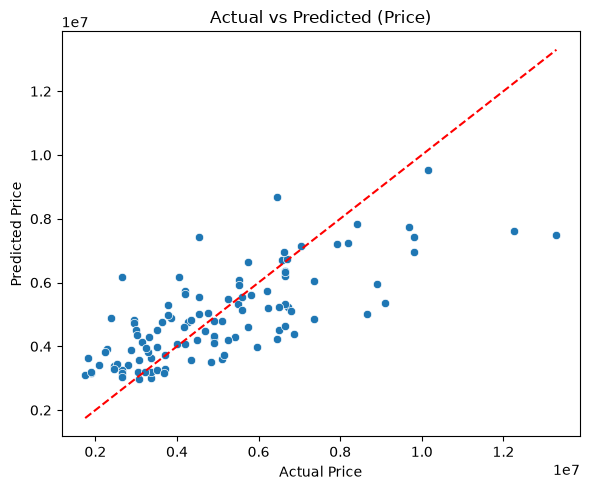

In [5]:
y_pred = model.predict(sm.add_constant(X_test))
mse = mean_squared_error(y_test, y_pred)
rmse, mae = np.sqrt(mse), mean_absolute_error(y_test, y_pred)
test_r2 = r2_score(y_test, y_pred)
print(f"Train R2: {model.rsquared:.4f} | Adj R2: {model.rsquared_adj:.4f}")
print(f"Test  R2: {test_r2:.4f} | RMSE: {rmse:.2f} | MAE: {mae:.2f}")

plt.figure(figsize=(6, 5))
sns.scatterplot(x=y_test, y=y_pred)
lims = [min(float(y_test.min()), float(y_pred.min())), max(float(y_test.max()), float(y_pred.max()))]
plt.plot(lims, lims, "r--")
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted (Price)")
plt.tight_layout()
plt.show()

    Variable    VIF
1       area  1.158
2   bedrooms  1.332
3  bathrooms  1.270
4    stories  1.241
5    parking  1.154


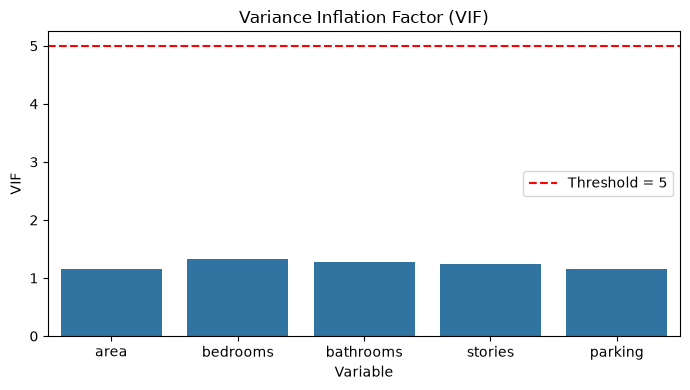

In [6]:
X_vif = sm.add_constant(X_train)
vif = pd.DataFrame({
    "Variable": X_vif.columns,
    "VIF": [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
})
vif = vif[vif["Variable"] != "const"]
print(vif.round(3))

plt.figure(figsize=(7, 4))
sns.barplot(data=vif, x="Variable", y="VIF")
plt.axhline(5, color="red", linestyle="--", label="Threshold = 5")
plt.title("Variance Inflation Factor (VIF)")
plt.legend()
plt.tight_layout()
plt.show()

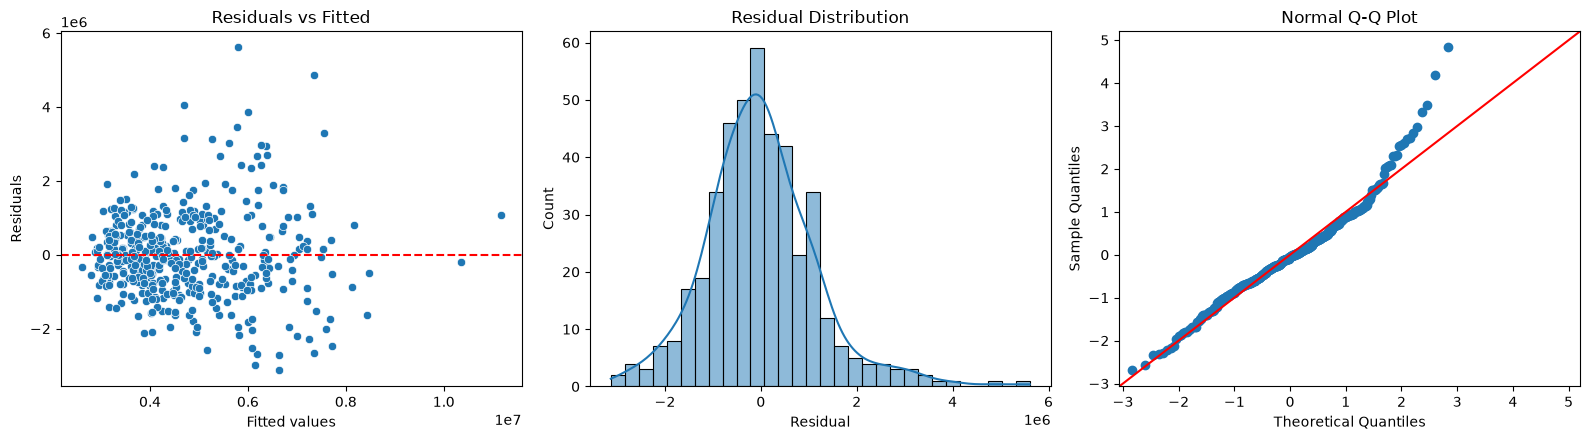

In [7]:
fitted, residuals = model.fittedvalues, model.resid
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.scatterplot(x=fitted, y=residuals, ax=axes[0])
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set(xlabel="Fitted values", ylabel="Residuals", title="Residuals vs Fitted")

sns.histplot(residuals, bins=30, kde=True, ax=axes[1])
axes[1].set(xlabel="Residual", title="Residual Distribution")

sm.qqplot(residuals, line="45", fit=True, ax=axes[2])
axes[2].set(title="Normal Q-Q Plot")
plt.tight_layout()
plt.show()

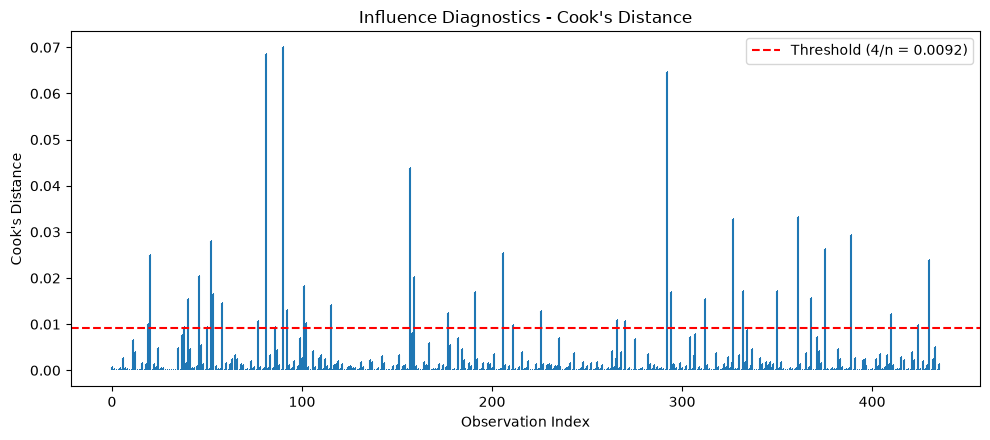

Influential observations count: 39


In [8]:
influence = OLSInfluence(model)
diagnostics = pd.DataFrame({
    "Actual": y_train,
    "Fitted": fitted,
    "Residual": residuals,
    "Std. Residual": influence.resid_studentized_internal,
    "Cook's D": influence.cooks_distance[0]
})
n = len(X_train)
threshold = 4 / n

plt.figure(figsize=(10, 4.5))
plt.stem(np.arange(n), diagnostics["Cook's D"], markerfmt=",", basefmt=" ")
plt.axhline(threshold, color="red", linestyle="--", label=f"Threshold (4/n = {threshold:.4f})")
plt.xlabel("Observation Index")
plt.ylabel("Cook's Distance")
plt.title("Influence Diagnostics - Cook's Distance")
plt.legend()
plt.tight_layout()
plt.show()

influential = diagnostics[diagnostics["Cook's D"] > threshold]
print("Influential observations count:", len(influential))

In [9]:
summary = pd.DataFrame({
    "Metric": ["Training R2", "Adjusted R2", "Test R2", "Test MSE", "Test RMSE", "Test MAE", "Maximum VIF", "Influential observations"],
    "Value": [model.rsquared, model.rsquared_adj, test_r2, mse, rmse, mae, vif["VIF"].max(), len(influential)]
})
print(summary)

coefficients.to_csv("regression_coefficients.csv")
vif.to_csv("vif_results.csv", index=False)
diagnostics.to_csv("regression_diagnostics.csv")
summary.to_csv("regression_summary.csv", index=False)
print("Saved regression results to CSV files.")

                     Metric         Value
0               Training R2  5.621679e-01
1               Adjusted R2  5.570768e-01
2                   Test R2  5.464062e-01
3                  Test MSE  2.292722e+12
4                 Test RMSE  1.514174e+06
5                  Test MAE  1.127483e+06
6               Maximum VIF  1.332267e+00
7  Influential observations  3.900000e+01
Saved regression results to CSV files.
